# Lab 05 – Tổng hợp Tic-Tac-Toe: so sánh các chiến lược tìm kiếm đối kháng

Notebook này thực hiện **mục 4 và 5 của đề bài**: lập bảng tổng hợp các tác tử Tic-Tac-Toe trên **cùng điều kiện thí nghiệm**, trả lời các câu hỏi thảo luận và đưa ra các nhận xét về chất lượng nước đi, số nút, thời gian và khả năng mở rộng.

* Mỗi tác tử đấu với `random_player` **100 ván khi đi trước (X) và 100 ván khi đi sau (O)** (tổng 200 ván/tác tử, đáp ứng yêu cầu ≥ 100 ván); *Random vs. Random* chạy 1000 ván vì rất nhẹ.
* Mã của các tác tử được lấy từ các notebook tương ứng (Random, AND-OR, Alpha-Beta, Heuristic Alpha-Beta, Pure Monte Carlo Search, UCB1/MCTS độ sâu 1), chỉ thêm bộ đếm số nút và đo thời gian.
* Seed cố định (`np.random.seed(2026)`) trước mỗi thí nghiệm để kết quả tái lập được; **thời gian phụ thuộc máy chạy**, còn số nút và tỉ lệ thắng/hòa/thua mới là thước đo ổn định.
* Hướng dẫn chạy toàn bộ bài lab: xem file `HUONG_DAN_CHAY.md`.

In [1]:
import math, time, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown
import tictactoe
from tictactoe import empty_board, actions, result, terminal, utility, other, random_player, play, check_board

NODES = {}          # bộ đếm số nút của từng thuật toán (được đặt lại ở mỗi lần gọi)

# ---------------- Minimax (không cắt tỉa) – chỉ dùng để so sánh số nút / kiểm tra Alpha-Beta ----------------
def minimax_search(board, player = 'x'):
    NODES["Minimax"] = 0
    def max_value(state):
        NODES["Minimax"] += 1
        v = utility(state, player)
        if v is not None: return v, None
        v, move = -math.inf, None
        for a in actions(state):
            v2, _ = min_value(result(state, player, a))
            if v2 > v: v, move = v2, a
        return v, move
    def min_value(state):
        NODES["Minimax"] += 1
        v = utility(state, player)
        if v is not None: return v, None
        v, move = +math.inf, None
        for a in actions(state):
            v2, _ = max_value(result(state, other(player), a))
            if v2 < v: v, move = v2, a
        return v, move
    value, move = max_value(board)
    return {"move": move, "value": value}

# ---------------- AND-OR search (draw_is_win = True) ----------------
def results(state, action, player = 'x'):
    opponent = other(player)
    state = state.copy()
    state[action] = player
    r = list()
    o_actions = actions(state)
    if len(o_actions) < 1: return [state]
    for o_a in o_actions:
        s = state.copy(); s[o_a] = opponent
        r.append(s)
    return r

def and_or_search(state, player = 'x', draw_is_win = True):
    NODES["AND-OR"] = 0
    return or_search(state, player, draw_is_win)

def or_search(state, player, draw_is_win):
    NODES["AND-OR"] += 1
    u = utility(state, player)
    if u == -1 or (not draw_is_win and u == 0): return None
    for action in actions(state):
        plan = and_search(results(state, action, player), player, draw_is_win)
        if plan is not None: return [action, plan]
    return None

def and_search(states, player, draw_is_win):
    NODES["AND-OR"] += 1
    plans = []
    for s in states:
        u = utility(s, player)
        if u == 1: return "win"
        if draw_is_win and u == 0: return "draw"
        plan = or_search(s, player, draw_is_win)
        if plan is None: return None
        plans.append(['if', s, 'then', plan])
    return plans

def and_or_player(board, player = 'x'):
    plan = and_or_search(board, player)
    if plan is None: return np.random.choice(actions(board))      # không có kế hoạch đảm bảo → đi ngẫu nhiên
    return plan[0]

# ---------------- Alpha-Beta đầy đủ ----------------
def alpha_beta_search(board, player = 'x'):
    NODES["Alpha-Beta"] = 0
    def max_value_ab(state, alpha, beta):
        NODES["Alpha-Beta"] += 1
        v = utility(state, player)
        if v is not None: return v, None
        v, move = -math.inf, None
        for a in actions(state):
            v2, _ = min_value_ab(result(state, player, a), alpha, beta)
            if v2 > v:
                v, move = v2, a
                alpha = max(alpha, v)
            if v >= beta: return v, move
        return v, move
    def min_value_ab(state, alpha, beta):
        NODES["Alpha-Beta"] += 1
        v = utility(state, player)
        if v is not None: return v, None
        v, move = +math.inf, None
        for a in actions(state):
            v2, _ = max_value_ab(result(state, other(player), a), alpha, beta)
            if v2 < v:
                v, move = v2, a
                beta = min(beta, v)
            if v <= alpha: return v, move
        return v, move
    value, move = max_value_ab(board, -math.inf, +math.inf)
    return {"move": move, "value": value}

def alpha_beta_player(board, player = 'x'):
    return alpha_beta_search(board, player)["move"]

# ---------------- Heuristic Alpha-Beta (cutoff + hàm đánh giá của notebook heuristic) ----------------
def eval_fun(state, player = 'x'):
    u = utility(state, player)
    if u is not None: return u, True
    score = 0
    board = np.array(state).reshape((3, 3))
    diagonals = np.array([[board[i][i] for i in range(len(board))], [board[i][len(board) - i - 1] for i in range(len(board))]])
    for a_board in [board, np.transpose(board), diagonals]:
        for row in a_board:
            if sum(row == player) == 2 and any(row == ' '): score += .4
            if sum(row == other(player)) == 2 and any(row == ' '): score -= .4
    return score, False

def heuristic_search(board, cutoff, player = 'x'):
    key = f"Heuristic AB (cutoff {cutoff})"
    NODES[key] = 0
    def max_value_ab(state, alpha, beta, depth):
        NODES[key] += 1
        v, term = eval_fun(state, player)
        if depth >= cutoff or term: return v, None
        v, move = -math.inf, None
        for a in actions(state):
            v2, _ = min_value_ab(result(state, player, a), alpha, beta, depth + 1)
            if v2 > v:
                v, move = v2, a
                alpha = max(alpha, v)
            if v >= beta: return v, move
        return v, move
    def min_value_ab(state, alpha, beta, depth):
        NODES[key] += 1
        v, term = eval_fun(state, player)
        if depth >= cutoff or term: return v, None
        v, move = +math.inf, None
        for a in actions(state):
            v2, _ = max_value_ab(result(state, other(player), a), alpha, beta, depth + 1)
            if v2 < v:
                v, move = v2, a
                beta = min(beta, v)
            if v <= alpha: return v, move
        return v, move
    value, move = max_value_ab(board, -math.inf, +math.inf, 0)
    return {"move": move, "value": value}

def heuristic2_player(board, player = 'x'): return heuristic_search(board, 2, player)["move"]
def heuristic4_player(board, player = 'x'): return heuristic_search(board, 4, player)["move"]

# ---------------- Pure Monte Carlo Search và UCB1 (UCT độ sâu 1) ----------------
def playout(state, action, player = 'x'):
    state = result(state, player, action)
    current_player = other(player)
    while True:
        u = utility(state, player)
        if u is not None: return u
        state = result(state, current_player, np.random.choice(actions(state)))
        current_player = other(current_player)

def pmcs(board, N = 100, player = 'x'):
    NODES["Pure Monte Carlo"] = N
    acts = actions(board)
    n = math.floor(N / len(acts))
    ps = {i: np.mean([playout(board, i, player) for _ in range(n)]) for i in acts}
    return max(ps, key = ps.get)

def UCT_depth1(board, N = 100, player = 'x'):
    NODES["UCB1/MCTS"] = N
    C = math.sqrt(2)
    acts = actions(board)
    u = [0] * len(acts); n = [0] * len(acts); n_parent = 0
    UCB1 = [+math.inf] * len(acts)
    for i in range(N):
        action_id = UCB1.index(max(UCB1))
        p = playout(board, acts[action_id], player = player)
        u[action_id] += p; n[action_id] += 1; n_parent += 1
        for k in range(len(acts)):
            if n[k] > 0: UCB1[k] = u[k] / n[k] + C * math.sqrt(math.log(n_parent) / n[k])
    return acts[n.index(max(n))]

def pmcs100_player(board, player = 'x'): return pmcs(board, 100, player)
def ucb1_100_player(board, player = 'x'): return UCT_depth1(board, 100, player)
print("Đã định nghĩa xong các tác tử.")

Đã định nghĩa xong các tác tử.


## 1. Số nút và thời gian của MỘT lần chọn nước đi ở bàn cờ rỗng (X đi trước)

Đây là tình huống khó nhất của Tic-Tac-Toe (cây trò chơi lớn nhất). Cột *Số nút / playout* là số nút đã duyệt (với Minimax, AND-OR, Alpha-Beta, Heuristic) hoặc số playout (với PMCS, UCB1).

In [2]:
def one_call(name, fn, key):
    t0 = time.perf_counter(); mv = fn(empty_board(), 'x'); dt = (time.perf_counter() - t0) * 1000
    return {"Thuật toán": name, "Nước chọn": int(mv), "Số nút / playout": int(NODES[key]), "Thời gian (ms)": round(dt, 1)}

np.random.seed(2026)
first = pd.DataFrame([
    one_call("Minimax (không cắt tỉa)",       lambda b, p: minimax_search(b, p)["move"], "Minimax"),
    one_call("AND-OR (draw_is_win = True)",   and_or_player,       "AND-OR"),
    one_call("Alpha-Beta",                    alpha_beta_player,   "Alpha-Beta"),
    one_call("Heuristic AB (cutoff 4)",       heuristic4_player,   "Heuristic AB (cutoff 4)"),
    one_call("Heuristic AB (cutoff 2)",       heuristic2_player,   "Heuristic AB (cutoff 2)"),
    one_call("Pure Monte Carlo (N = 100)",    pmcs100_player,      "Pure Monte Carlo"),
    one_call("UCB1/MCTS (N = 100)",           ucb1_100_player,     "UCB1/MCTS"),
])
first["Số nút / playout"] = first["Số nút / playout"].map("{:,}".format).str.replace(",", ".")
display(first)

,Thuật toán,Nước chọn,Số nút / playout,Thời gian (ms)
0,Minimax (không cắt tỉa),0,549.946,9534.1
1,AND-OR (draw_is_win = True),0,966,21.6
2,Alpha-Beta,0,18.297,296.0
3,Heuristic AB (cutoff 4),4,541,32.6
4,Heuristic AB (cutoff 2),0,26,1.6
5,Pure Monte Carlo (N = 100),4,100,17.9
6,UCB1/MCTS (N = 100),8,100,18.6


## 2. Bảng tổng hợp: mỗi tác tử đấu với Random (≥ 100 ván mỗi vai)

In [3]:
GAMES = 100                 # số ván cho mỗi vai (X và O)
SEED = 2026

def instrumented(agent, key):
    st = {"t": 0.0, "n": 0, "nodes": 0, "tmax": 0.0}
    def f(board, player = 'x'):
        t = time.perf_counter(); a = agent(board, player); dt = time.perf_counter() - t
        st["t"] += dt; st["n"] += 1; st["tmax"] = max(st["tmax"], dt)
        if key: st["nodes"] += NODES[key]
        return a
    return f, st

AGENTS = [   # (tên, hàm, khóa bộ đếm nút)
    ("AND-OR",                    and_or_player,      "AND-OR"),
    ("Alpha-Beta",                alpha_beta_player,  "Alpha-Beta"),
    ("Heuristic Alpha-Beta (cutoff 4)", heuristic4_player, "Heuristic AB (cutoff 4)"),
    ("Heuristic Alpha-Beta (cutoff 2)", heuristic2_player, "Heuristic AB (cutoff 2)"),
    ("Pure Monte Carlo (N = 100)", pmcs100_player,    "Pure Monte Carlo"),
    ("UCB1/MCTS (N = 100)",        ucb1_100_player,   "UCB1/MCTS"),
]

detail, rows = [], []
# --- Random vs. Random (1000 ván, nhìn từ phía X) ---
np.random.seed(SEED)
fx, sx = instrumented(random_player, None); fo, so = instrumented(random_player, None)
r = play(fx, fo, N = 1000)
rows.append({"Tác tử / Thuật toán": "Random", "Đối thủ": "Random", "Số ván": 1000, "Thắng": r['x'], "Hòa": r['d'], "Thua": r['o'],
             "Thời gian TB / nước (ms)": 1000 * (sx["t"] + so["t"]) / (sx["n"] + so["n"]), "Số nút TB / nước": None})
# --- các tác tử còn lại: 100 ván mỗi vai ---
for name, agent, key in AGENTS:
    np.random.seed(SEED)
    tot = {"win": 0, "draw": 0, "loss": 0, "t": 0.0, "n": 0, "nodes": 0, "tmax": 0.0}
    for role in ('x', 'o'):
        f, st = instrumented(agent, key)
        r = play(f, random_player, N = GAMES) if role == 'x' else play(random_player, f, N = GAMES)
        w, l = (r['x'], r['o']) if role == 'x' else (r['o'], r['x'])
        detail.append({"Tác tử": name, "Vai": role, "Số ván": GAMES, "Thắng": w, "Hòa": r['d'], "Thua": l,
                       "Thời gian TB / nước (ms)": round(1000 * st["t"] / st["n"], 2), "Thời gian lâu nhất (ms)": round(1000 * st["tmax"], 1),
                       "Số nút TB / nước": round(st["nodes"] / st["n"])})
        tot["win"] += w; tot["draw"] += r['d']; tot["loss"] += l
        tot["t"] += st["t"]; tot["n"] += st["n"]; tot["nodes"] += st["nodes"]; tot["tmax"] = max(tot["tmax"], st["tmax"])
    rows.append({"Tác tử / Thuật toán": name, "Đối thủ": "Random", "Số ván": 2 * GAMES, "Thắng": tot["win"], "Hòa": tot["draw"], "Thua": tot["loss"],
                 "Thời gian TB / nước (ms)": 1000 * tot["t"] / tot["n"], "Số nút TB / nước": tot["nodes"] / tot["n"]})

detail = pd.DataFrame(detail)
summary = pd.DataFrame(rows)
fmt = summary.copy()
for c in ("Thắng", "Hòa", "Thua"):
    fmt[c] = [f"{v} ({100 * v / g:.1f}%)" for v, g in zip(summary[c], summary["Số ván"])]
fmt["Thời gian TB / nước (ms)"] = summary["Thời gian TB / nước (ms)"].map(lambda v: f"{v:.3f}" if v < 0.1 else f"{v:.2f}")
fmt["Số nút TB / nước"] = summary["Số nút TB / nước"].map(lambda v: "—" if v is None or (isinstance(v, float) and np.isnan(v)) else f"{v:,.0f}".replace(",", "."))
display(fmt)
print("Ghi chú: 'Random vs Random' tính theo X (đi trước); với PMCS/UCB1 'Số nút' là số playout mỗi nước (N = 100).")

,Tác tử / Thuật toán,Đối thủ,Số ván,Thắng,Hòa,Thua,Thời gian TB / nước (ms),Số nút TB / nước
0,Random,Random,1000,596 (59.6%),122 (12.2%),282 (28.2%),0.017,—
1,AND-OR,Random,200,169 (84.5%),31 (15.5%),0 (0.0%),8.57,392
2,Alpha-Beta,Random,200,186 (93.0%),14 (7.0%),0 (0.0%),58.82,3.208
3,Heuristic Alpha-Beta (cutoff 4),Random,200,182 (91.0%),18 (9.0%),0 (0.0%),12.65,192
4,Heuristic Alpha-Beta (cutoff 2),Random,200,181 (90.5%),19 (9.5%),0 (0.0%),1.38,21
5,Pure Monte Carlo (N = 100),Random,200,182 (91.0%),8 (4.0%),10 (5.0%),13.29,100
6,UCB1/MCTS (N = 100),Random,200,185 (92.5%),7 (3.5%),8 (4.0%),13.19,100


Ghi chú: 'Random vs Random' tính theo X (đi trước); với PMCS/UCB1 'Số nút' là số playout mỗi nước (N = 100).


### Chi tiết theo vai (X đi trước / O đi sau)

In [4]:
display(detail)

,Tác tử,Vai,Số ván,Thắng,Hòa,Thua,Thời gian TB / nước (ms),Thời gian lâu nhất (ms),Số nút TB / nước
0,AND-OR,x,100,98,2,0,7.03,28.1,315
1,AND-OR,o,100,71,29,0,10.03,71.8,466
2,Alpha-Beta,x,100,99,1,0,102.70,429.5,5595
3,Alpha-Beta,o,100,87,13,0,18.41,135.8,1010
4,Heuristic Alpha-Beta (cutoff 4),x,100,99,1,0,14.40,41.3,225
5,Heuristic Alpha-Beta (cutoff 4),o,100,83,17,0,10.75,67.6,156
6,Heuristic Alpha-Beta (cutoff 2),x,100,97,3,0,1.48,2.8,21
7,Heuristic Alpha-Beta (cutoff 2),o,100,84,16,0,1.28,2.6,20
8,Pure Monte Carlo (N = 100),x,100,99,1,0,14.57,40.0,100
9,Pure Monte Carlo (N = 100),o,100,83,7,10,11.91,36.0,100


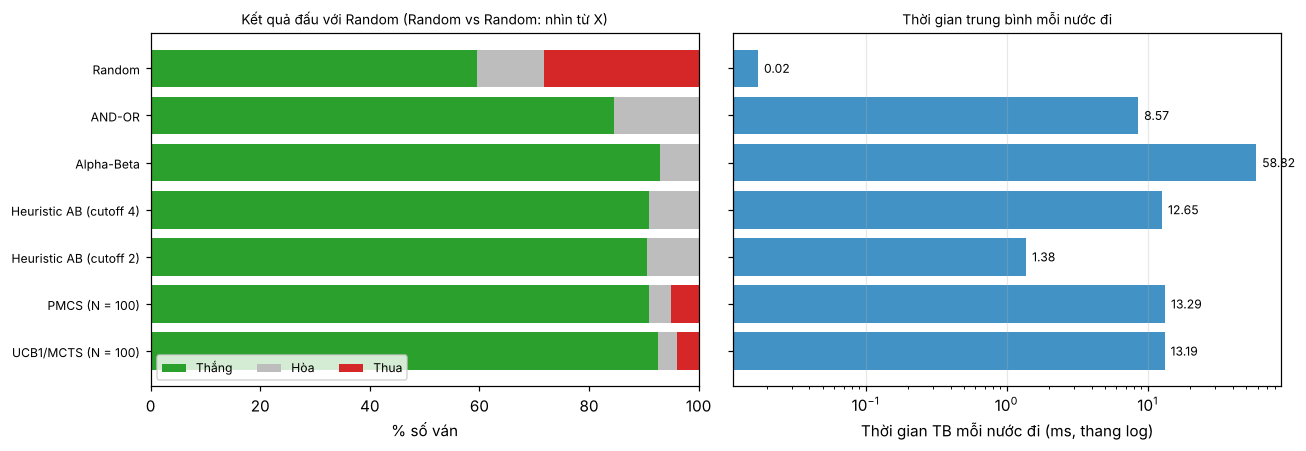

In [5]:
# ---------- Biểu đồ: tỉ lệ thắng/hòa/thua và thời gian mỗi nước ----------
names = list(summary["Tác tử / Thuật toán"])
short = [n.replace("Heuristic Alpha-Beta", "Heuristic AB").replace("Pure Monte Carlo", "PMCS") for n in names]
win = 100 * summary["Thắng"] / summary["Số ván"]; dr = 100 * summary["Hòa"] / summary["Số ván"]; lo = 100 * summary["Thua"] / summary["Số ván"]
fig, ax = plt.subplots(1, 2, figsize = (12, 4.2), dpi = 110)
y = np.arange(len(names))[::-1]
ax[0].barh(y, win, color = "#2ca02c", label = "Thắng"); ax[0].barh(y, dr, left = win, color = "#bdbdbd", label = "Hòa"); ax[0].barh(y, lo, left = win + dr, color = "#d62728", label = "Thua")
ax[0].set_yticks(y); ax[0].set_yticklabels(short, fontsize = 8); ax[0].set_xlabel("% số ván"); ax[0].set_xlim(0, 100)
ax[0].set_title("Kết quả đấu với Random (Random vs Random: nhìn từ X)", fontsize = 9); ax[0].legend(fontsize = 8, loc = "lower left", ncol = 3)
ax[1].barh(y, summary["Thời gian TB / nước (ms)"], color = "#4292c6"); ax[1].set_xscale("log")
ax[1].set_yticks(y); ax[1].set_yticklabels([]); ax[1].set_xlabel("Thời gian TB mỗi nước đi (ms, thang log)")
ax[1].set_title("Thời gian trung bình mỗi nước đi", fontsize = 9); ax[1].grid(axis = "x", alpha = .3)
for yy, v in zip(y, summary["Thời gian TB / nước (ms)"]): ax[1].text(v * 1.1, yy, f"{v:.2f}", va = "center", fontsize = 8)
plt.tight_layout(); plt.show()

## 3. Kiểm tra: Alpha-Beta có thay đổi nước đi của Minimax không?

So sánh nước đi và giá trị của Minimax (không cắt tỉa) với Alpha-Beta trên **200 thế cờ ngẫu nhiên** (các thế cờ có tối đa 6 ô trống để Minimax chạy nhanh) và trên 5 thế cờ kiểm thử của giảng viên.

In [6]:
# thu thập mọi thế cờ đạt được từ bàn cờ rỗng (BFS) rồi lấy mẫu ngẫu nhiên các thế cờ chưa kết thúc có ≤ 6 ô trống
start = tuple(empty_board())
seen, frontier = {start: 'x'}, [(start, 'x')]
while frontier:
    nxt = []
    for s, p in frontier:
        if check_board(list(s)) != 'n': continue
        for a in actions(list(s)):
            c = list(s); c[a] = p; c = tuple(c)
            if c not in seen: seen[c] = other(p); nxt.append((c, other(p)))
    frontier = nxt
pool = [(list(s), p) for s, p in seen.items() if check_board(list(s)) == 'n' and 0 < len(actions(list(s))) <= 6]
sample = random.Random(2026).sample(pool, 200)

diff, nodes_mm, nodes_ab = 0, 0, 0
for b, p in sample:
    m1 = minimax_search(b, p); n1 = NODES["Minimax"]
    m2 = alpha_beta_search(b, p); n2 = NODES["Alpha-Beta"]
    nodes_mm += n1; nodes_ab += n2
    diff += (m1["move"] != m2["move"]) or (m1["value"] != m2["value"])

def board_from(x, o):
    b = empty_board()
    for i in x: b[i] = 'x'
    for i in o: b[i] = 'o'
    return b
tests = {"X sắp thắng": board_from([0, 4], [1, 3]), "O sắp thắng": board_from([4, 8], [0, 1, 3]), "X cần tìm đường hòa": board_from([0, 2], [1, 4]),
         "Tình huống bất lợi": board_from([2], [0, 8]), "Bàn cờ rỗng": empty_board()}
trows = []
for name, b in tests.items():
    m1 = minimax_search(b); n1 = NODES["Minimax"]; m2 = alpha_beta_search(b); n2 = NODES["Alpha-Beta"]
    trows.append({"Trạng thái": name, "Minimax: nước / giá trị": f"{m1['move']} / {m1['value']:+d}", "Alpha-Beta: nước / giá trị": f"{m2['move']} / {m2['value']:+d}",
                  "Nút Minimax": n1, "Nút Alpha-Beta": n2, "Giống nhau?": (m1['move'], m1['value']) == (m2['move'], m2['value'])})
display(pd.DataFrame(trows))
print(f"200 thế cờ ngẫu nhiên: số trường hợp Alpha-Beta KHÁC Minimax (nước hoặc giá trị) = {diff}; tổng số nút {nodes_mm:,} (Minimax) so với {nodes_ab:,} (Alpha-Beta) → giảm {100 * (1 - nodes_ab / nodes_mm):.1f}%")

,Trạng thái,Minimax: nước / giá trị,Alpha-Beta: nước / giá trị,Nút Minimax,Nút Alpha-Beta,Giống nhau?
0,X sắp thắng,2 / +1,2 / +1,190,61,True
1,O sắp thắng,2 / -1,2 / -1,33,15,True
2,X cần tìm đường hòa,7 / +0,7 / +0,206,101,True
3,Tình huống bất lợi,1 / -1,1 / -1,941,238,True
4,Bàn cờ rỗng,0 / +0,0 / +0,549946,18297,True


200 thế cờ ngẫu nhiên: số trường hợp Alpha-Beta KHÁC Minimax (nước hoặc giá trị) = 0; tổng số nút 20,929 (Minimax) so với 7,217 (Alpha-Beta) → giảm 65.5%


## 4. Trả lời các câu hỏi thảo luận

In [7]:
nodes_first = first.set_index("Thuật toán")["Số nút / playout"]
rowmap = {r["Tác tử / Thuật toán"]: r for _, r in summary.iterrows()}
pct = lambda name, col: 100 * rowmap[name][col] / rowmap[name]["Số ván"]
ms = lambda name: rowmap[name]["Thời gian TB / nước (ms)"]
nd = lambda name: rowmap[name]["Số nút TB / nước"]
vn = lambda x, d = 1: f"{x:,.{d}f}".replace(",", "_").replace(".", ",").replace("_", ".")

h_note = ("cutoff càng nông và heuristic càng thô thì quyết định càng kém (và thua nhiều hơn ở các thế cờ khó)."
          if pct('Heuristic Alpha-Beta (cutoff 2)', 'Thua') > pct('Heuristic Alpha-Beta (cutoff 4)', 'Thua')
          else "ở mức thử nghiệm này (đối thủ Random yếu) cutoff nông chưa làm tăng số ván thua, nhưng nó kém tin cậy hơn ở các thế cờ khó (xem notebook heuristic).")
# Connect 4 / Dots and Boxes – tính trực tiếp các con số minh họa
c4_depth, c4_b = 42, 7
db_lines = lambda r, c: r * (c + 1) + c * (r + 1)          # số đoạn thẳng của bàn r × c ô vuông
db = {k: db_lines(*k) for k in [(2, 2), (3, 3), (4, 4), (5, 5)]}

display(Markdown(f"""
**1. Minimax khác AND-OR Search ở cách mô hình hóa đối thủ như thế nào?**
* **Minimax** coi đối thủ là một **người chơi đối kháng có mục tiêu ngược lại** (nút MIN): trò chơi tổng bằng 0 nên đối thủ luôn chọn nước làm *giảm tối đa* utility của ta. Kết quả là **một giá trị số** (+1/0/−1) và **một nước đi tốt nhất** trước đối thủ tối ưu.
* **AND-OR Search** coi đối thủ là một phần của **môi trường không xác định**: sau nước đi của ta, môi trường có thể rơi vào *bất kỳ* trạng thái nào trong một **tập** (nút AND = phải xử lý **mọi** phản ứng của đối thủ; nút OR = ta **chọn** một hành động). Kết quả là một **kế hoạch có điều kiện** ("nếu đối thủ đi ô a thì đi ô b …") đảm bảo đạt trạng thái đích (thắng, hoặc hòa nếu `draw_is_win = True`) cho mọi phản ứng; không có giá trị số, không xếp hạng các nước cùng đạt đích và dừng ở kế hoạch đầu tiên tìm được.
* Với trò chơi tổng bằng 0 như Tic-Tac-Toe hai cách cho cùng *đảm bảo kết quả* (cả hai không bao giờ thua khi đi trước/sau), nhưng AND-OR tổng quát hơn (đối thủ không cần có hàm mục tiêu; áp dụng được cho môi trường ngẫu nhiên/không đối kháng) còn Minimax cho thông tin *định lượng* hơn. Ở bàn cờ rỗng Minimax duyệt {nodes_first['Minimax (không cắt tỉa)']} nút so với {nodes_first['AND-OR (draw_is_win = True)']} nút của AND-OR (AND-OR dừng sớm khi đã tìm được kế hoạch).

**2. Alpha-Beta có làm thay đổi nước đi tối ưu của Minimax không? Vì sao?**
* **Không.** Trên 200 thế cờ ngẫu nhiên có {diff} trường hợp khác nhau (cả nước đi lẫn giá trị), và giảm số nút {vn(100 * (1 - nodes_ab / nodes_mm))} %; ở bàn cờ rỗng Minimax duyệt {nodes_first['Minimax (không cắt tỉa)']} nút còn Alpha-Beta chỉ {nodes_first['Alpha-Beta']} nút.
* **Vì sao:** Alpha-Beta chỉ bỏ qua những nhánh mà ta chứng minh được **không thể ảnh hưởng đến giá trị ở gốc** (khi α ≥ β thì MIN/MAX ở trên sẽ không bao giờ chọn nhánh đó). Do đó giá trị gốc giống hệt Minimax; và nước đi trả về cũng là nước *đầu tiên đạt giá trị tối ưu theo thứ tự duyệt*, đúng như Minimax (vì so sánh `>` chặt). Phần *hiệu quả* thì phụ thuộc thứ tự duyệt nước đi (move ordering) – xem thí nghiệm ở notebook Alpha-Beta (cùng một cây nhưng số nút khác nhau gấp ≈ 6 lần giữa thứ tự tốt nhất và tệ nhất).

**3. Khi nào cần dùng heuristic và cutoff thay vì tìm kiếm tới trạng thái kết thúc?**
* Khi **cây trò chơi quá lớn để duyệt đến trạng thái kết thúc trong thời gian cho phép**. Với Tic-Tac-Toe điều này không cần thiết (Alpha-Beta đầy đủ chỉ cần ≈ {nodes_first['Alpha-Beta']} nút ở thế cờ khó nhất), nhưng với Connect 4 (độ sâu tối đa {c4_depth}, tối đa {c4_b} nước/lượt ⇒ {c4_b}^{c4_depth} ≈ {c4_b ** c4_depth:.1e} đường đi), cờ vua, cờ vây… thì không khả thi nên phải **cắt ở độ sâu d** và dùng **hàm heuristic** ước lượng giá trị thế cờ.
* Cái giá phải trả: mất đảm bảo tối ưu và chất lượng phụ thuộc vào heuristic. Trong bảng trên, Heuristic AB cutoff 4 chỉ duyệt {vn(nd('Heuristic Alpha-Beta (cutoff 4)'), 0)} nút/nước (so với {vn(nd('Alpha-Beta'), 0)} của Alpha-Beta đầy đủ) mà vẫn thắng {vn(pct('Heuristic Alpha-Beta (cutoff 4)', 'Thắng'))} % (Alpha-Beta: {vn(pct('Alpha-Beta', 'Thắng'))} %); cutoff 2 nhanh hơn nữa ({vn(ms('Heuristic Alpha-Beta (cutoff 2)'), 2)} ms/nước) và thua {vn(pct('Heuristic Alpha-Beta (cutoff 2)', 'Thua'))} % số ván ({vn(pct('Heuristic Alpha-Beta (cutoff 4)', 'Thua'))} % với cutoff 4) – {h_note}

**4. Pure Monte Carlo Search có ưu điểm gì so với heuristic search? Hạn chế chính là gì?**
* **Ưu điểm:** không cần hàm heuristic thủ công hay hiểu biết chuyên môn (chỉ cần mô phỏng được luật chơi); chi phí kiểm soát được bằng số playout N (thuật toán "anytime"), không phụ thuộc trực tiếp vào độ sâu/độ rộng của cây nên dùng được cho trò chơi lớn.
* **Hạn chế:** kết quả **ngẫu nhiên**, **không đảm bảo tối ưu**; sai số giảm chậm (∝ 1/√N, thời gian tăng tuyến tính theo N); chính sách playout ngẫu nhiên *đánh giá thế cờ như thể đối thủ chơi tệ* nên có thể bỏ qua nước chặn bắt buộc hoặc đi nước "đánh cược" (xem thế cờ "tình huống bất lợi" và ván G4 ở notebook tương tác). Ở đây PMCS (N = 100) thắng {vn(pct('Pure Monte Carlo (N = 100)', 'Thắng'))} % và thua {vn(pct('Pure Monte Carlo (N = 100)', 'Thua'))} % số ván trong khi Alpha-Beta không thua ván nào ({vn(pct('Alpha-Beta', 'Thua'))} %).

**5. UCB1 cải thiện việc phân bổ số lần mô phỏng so với chia đều playout như thế nào?**
* PMCS chia đều N playout cho mọi nước kể cả các nước đã rõ là tệ. UCB1 chọn nước có chỉ số *điểm trung bình + thưởng khám phá* lớn nhất ở mỗi lần mô phỏng nên **dồn dần ngân sách vào các nước hứa hẹn** nhưng vẫn thử lại các nước ít được thăm (ở notebook UCB1: ≈ 80 % playout dồn vào nước đúng ở N = 1000 so với 20 % của PMCS).
* Với Tic-Tac-Toe (rất nhỏ) chất lượng quyết định cuối cùng của UCB1 và PMCS gần như tương đương (UCB1: thắng {vn(pct('UCB1/MCTS (N = 100)', 'Thắng'))} %, thua {vn(pct('UCB1/MCTS (N = 100)', 'Thua'))} %; PMCS: thắng {vn(pct('Pure Monte Carlo (N = 100)', 'Thắng'))} %, thua {vn(pct('Pure Monte Carlo (N = 100)', 'Thua'))} %, cùng N = 100) – lợi thế của UCB1 lộ rõ khi số nước đi lớn, cây sâu hoặc mỗi playout tốn kém, và là nền tảng để mở rộng thành UCT/MCTS đầy đủ (mở rộng cây nhiều tầng).

**6. Trong Connect 4 và Dots and Boxes, yếu tố nào làm không gian tìm kiếm tăng nhanh nhất?**
* **Connect 4 (6 × 7):** *độ sâu* (tối đa {c4_depth} lượt) kết hợp với hệ số nhánh ≈ {c4_b} làm số đường đi tăng *theo hàm mũ* ({c4_b}^{c4_depth} ≈ {c4_b ** c4_depth:.1e}); số thế cờ khác nhau thực tế "chỉ" ≈ 4,5·10¹² nhờ nhiều đường đi dẫn đến cùng thế cờ (transposition) và luật trọng lực/luật kết thúc ván. Tăng kích thước bàn (thêm cột/hàng) làm *cả độ sâu lẫn hệ số nhánh* tăng.
* **Dots and Boxes:** hệ số nhánh là **số đoạn thẳng còn lại** (không bị trọng lực hạn chế) và độ sâu = tổng số đoạn thẳng (bàn 2×2 ô: {db[(2, 2)]} đoạn; 3×3: {db[(3, 3)]}; 4×4: {db[(4, 4)]}; 5×5: {db[(5, 5)]}), nên số thứ tự đi có thể tới **giai thừa** ({db[(3, 3)]}! ≈ {math.factorial(db[(3, 3)]):.1e} với 3×3 ô), còn số thế cờ là 2^{db[(3, 3)]} ≈ {2 ** db[(3, 3)]:.1e} (mỗi đoạn thẳng có/không). Vì vậy **số đoạn thẳng (tăng theo diện tích bàn) là yếu tố làm không gian tìm kiếm bùng nổ nhanh nhất**, cộng thêm luật "ăn ô được đi tiếp" làm cây khó cắt tỉa bằng thứ tự lượt đơn giản.
* Hệ quả chung: cả hai trò chơi đều cần cutoff + heuristic, bảng chuyển vị (memoization), thứ tự nước đi tốt và/hoặc tìm kiếm Monte Carlo (xem các notebook `assignment_*.ipynb`).
"""))


**1. Minimax khác AND-OR Search ở cách mô hình hóa đối thủ như thế nào?**
* **Minimax** coi đối thủ là một **người chơi đối kháng có mục tiêu ngược lại** (nút MIN): trò chơi tổng bằng 0 nên đối thủ luôn chọn nước làm *giảm tối đa* utility của ta. Kết quả là **một giá trị số** (+1/0/−1) và **một nước đi tốt nhất** trước đối thủ tối ưu.
* **AND-OR Search** coi đối thủ là một phần của **môi trường không xác định**: sau nước đi của ta, môi trường có thể rơi vào *bất kỳ* trạng thái nào trong một **tập** (nút AND = phải xử lý **mọi** phản ứng của đối thủ; nút OR = ta **chọn** một hành động). Kết quả là một **kế hoạch có điều kiện** ("nếu đối thủ đi ô a thì đi ô b …") đảm bảo đạt trạng thái đích (thắng, hoặc hòa nếu `draw_is_win = True`) cho mọi phản ứng; không có giá trị số, không xếp hạng các nước cùng đạt đích và dừng ở kế hoạch đầu tiên tìm được.
* Với trò chơi tổng bằng 0 như Tic-Tac-Toe hai cách cho cùng *đảm bảo kết quả* (cả hai không bao giờ thua khi đi trước/sau), nhưng AND-OR tổng quát hơn (đối thủ không cần có hàm mục tiêu; áp dụng được cho môi trường ngẫu nhiên/không đối kháng) còn Minimax cho thông tin *định lượng* hơn. Ở bàn cờ rỗng Minimax duyệt 549.946 nút so với 966 nút của AND-OR (AND-OR dừng sớm khi đã tìm được kế hoạch).

**2. Alpha-Beta có làm thay đổi nước đi tối ưu của Minimax không? Vì sao?**
* **Không.** Trên 200 thế cờ ngẫu nhiên có 0 trường hợp khác nhau (cả nước đi lẫn giá trị), và giảm số nút 65,5 %; ở bàn cờ rỗng Minimax duyệt 549.946 nút còn Alpha-Beta chỉ 18.297 nút.
* **Vì sao:** Alpha-Beta chỉ bỏ qua những nhánh mà ta chứng minh được **không thể ảnh hưởng đến giá trị ở gốc** (khi α ≥ β thì MIN/MAX ở trên sẽ không bao giờ chọn nhánh đó). Do đó giá trị gốc giống hệt Minimax; và nước đi trả về cũng là nước *đầu tiên đạt giá trị tối ưu theo thứ tự duyệt*, đúng như Minimax (vì so sánh `>` chặt). Phần *hiệu quả* thì phụ thuộc thứ tự duyệt nước đi (move ordering) – xem thí nghiệm ở notebook Alpha-Beta (cùng một cây nhưng số nút khác nhau gấp ≈ 6 lần giữa thứ tự tốt nhất và tệ nhất).

**3. Khi nào cần dùng heuristic và cutoff thay vì tìm kiếm tới trạng thái kết thúc?**
* Khi **cây trò chơi quá lớn để duyệt đến trạng thái kết thúc trong thời gian cho phép**. Với Tic-Tac-Toe điều này không cần thiết (Alpha-Beta đầy đủ chỉ cần ≈ 18.297 nút ở thế cờ khó nhất), nhưng với Connect 4 (độ sâu tối đa 42, tối đa 7 nước/lượt ⇒ 7^42 ≈ 3.1e+35 đường đi), cờ vua, cờ vây… thì không khả thi nên phải **cắt ở độ sâu d** và dùng **hàm heuristic** ước lượng giá trị thế cờ.
* Cái giá phải trả: mất đảm bảo tối ưu và chất lượng phụ thuộc vào heuristic. Trong bảng trên, Heuristic AB cutoff 4 chỉ duyệt 192 nút/nước (so với 3.208 của Alpha-Beta đầy đủ) mà vẫn thắng 91,0 % (Alpha-Beta: 93,0 %); cutoff 2 nhanh hơn nữa (1,38 ms/nước) và thua 0,0 % số ván (0,0 % với cutoff 4) – ở mức thử nghiệm này (đối thủ Random yếu) cutoff nông chưa làm tăng số ván thua, nhưng nó kém tin cậy hơn ở các thế cờ khó (xem notebook heuristic).

**4. Pure Monte Carlo Search có ưu điểm gì so với heuristic search? Hạn chế chính là gì?**
* **Ưu điểm:** không cần hàm heuristic thủ công hay hiểu biết chuyên môn (chỉ cần mô phỏng được luật chơi); chi phí kiểm soát được bằng số playout N (thuật toán "anytime"), không phụ thuộc trực tiếp vào độ sâu/độ rộng của cây nên dùng được cho trò chơi lớn.
* **Hạn chế:** kết quả **ngẫu nhiên**, **không đảm bảo tối ưu**; sai số giảm chậm (∝ 1/√N, thời gian tăng tuyến tính theo N); chính sách playout ngẫu nhiên *đánh giá thế cờ như thể đối thủ chơi tệ* nên có thể bỏ qua nước chặn bắt buộc hoặc đi nước "đánh cược" (xem thế cờ "tình huống bất lợi" và ván G4 ở notebook tương tác). Ở đây PMCS (N = 100) thắng 91,0 % và thua 5,0 % số ván trong khi Alpha-Beta không thua ván nào (0,0 %).

**5. UCB1 cải thiện việc phân bổ số lần mô phỏng so với chia đều playout như thế nào?**
* PMCS chia đều N playout cho mọi nước kể cả các nước đã rõ là tệ. UCB1 chọn nước có chỉ số *điểm trung bình + thưởng khám phá* lớn nhất ở mỗi lần mô phỏng nên **dồn dần ngân sách vào các nước hứa hẹn** nhưng vẫn thử lại các nước ít được thăm (ở notebook UCB1: ≈ 80 % playout dồn vào nước đúng ở N = 1000 so với 20 % của PMCS).
* Với Tic-Tac-Toe (rất nhỏ) chất lượng quyết định cuối cùng của UCB1 và PMCS gần như tương đương (UCB1: thắng 92,5 %, thua 4,0 %; PMCS: thắng 91,0 %, thua 5,0 %, cùng N = 100) – lợi thế của UCB1 lộ rõ khi số nước đi lớn, cây sâu hoặc mỗi playout tốn kém, và là nền tảng để mở rộng thành UCT/MCTS đầy đủ (mở rộng cây nhiều tầng).

**6. Trong Connect 4 và Dots and Boxes, yếu tố nào làm không gian tìm kiếm tăng nhanh nhất?**
* **Connect 4 (6 × 7):** *độ sâu* (tối đa 42 lượt) kết hợp với hệ số nhánh ≈ 7 làm số đường đi tăng *theo hàm mũ* (7^42 ≈ 3.1e+35); số thế cờ khác nhau thực tế "chỉ" ≈ 4,5·10¹² nhờ nhiều đường đi dẫn đến cùng thế cờ (transposition) và luật trọng lực/luật kết thúc ván. Tăng kích thước bàn (thêm cột/hàng) làm *cả độ sâu lẫn hệ số nhánh* tăng.
* **Dots and Boxes:** hệ số nhánh là **số đoạn thẳng còn lại** (không bị trọng lực hạn chế) và độ sâu = tổng số đoạn thẳng (bàn 2×2 ô: 12 đoạn; 3×3: 24; 4×4: 40; 5×5: 60), nên số thứ tự đi có thể tới **giai thừa** (24! ≈ 6.2e+23 với 3×3 ô), còn số thế cờ là 2^24 ≈ 1.7e+07 (mỗi đoạn thẳng có/không). Vì vậy **số đoạn thẳng (tăng theo diện tích bàn) là yếu tố làm không gian tìm kiếm bùng nổ nhanh nhất**, cộng thêm luật "ăn ô được đi tiếp" làm cây khó cắt tỉa bằng thứ tự lượt đơn giản.
* Hệ quả chung: cả hai trò chơi đều cần cutoff + heuristic, bảng chuyển vị (memoization), thứ tự nước đi tốt và/hoặc tìm kiếm Monte Carlo (xem các notebook `assignment_*.ipynb`).


## 5. Nhận xét tổng hợp (chất lượng nước đi, số nút, thời gian, khả năng mở rộng)

In [8]:
ab, ao = 'Alpha-Beta', 'AND-OR'
h4, h2 = 'Heuristic Alpha-Beta (cutoff 4)', 'Heuristic Alpha-Beta (cutoff 2)'
pm, uc = 'Pure Monte Carlo (N = 100)', 'UCB1/MCTS (N = 100)'
rd = rowmap['Random']
fastest = min(['AND-OR', ab, h4, h2, pm, uc], key = ms)
dr = lambda name, role: int(detail[(detail["Tác tử"] == name) & (detail["Vai"] == role)]["Hòa"].iloc[0])
opt_loss = rowmap[ab]['Thua'] + rowmap[ao]['Thua']
opt_txt = "**không thua ván nào**" if opt_loss == 0 else f"chỉ thua {int(opt_loss)} ván (cần kiểm tra lại)"
display(Markdown(f"""
1. **Chất lượng nước đi.** Các thuật toán *đảm bảo tối ưu* (AND-OR, Alpha-Beta) {opt_txt} trong {int(rowmap[ab]['Số ván'])} ván đấu Random: thắng {vn(pct(ao, 'Thắng'))} % (AND-OR) và {vn(pct(ab, 'Thắng'))} % (Alpha-Beta), các ván còn lại là hòa – Alpha-Beta hòa {dr(ab, 'x')} ván khi đi trước và {dr(ab, 'o')} ván khi đi sau. Đi sau khó thắng hơn vì X có lợi thế đi trước nên chỉ thắng khi Random mắc lỗi; ngược lại người chơi Random thắng {vn(100 * rd['Thắng'] / rd['Số ván'])} % khi đi trước (Random vs. Random). Các phương pháp xấp xỉ (Heuristic cutoff 2, PMCS, UCB1) vẫn thắng {vn(pct(h2, 'Thắng'))} %, {vn(pct(pm, 'Thắng'))} % và {vn(pct(uc, 'Thắng'))} % nhưng có thể thua: {vn(pct(h2, 'Thua'))} % (cutoff 2), {vn(pct(pm, 'Thua'))} % (PMCS) và {vn(pct(uc, 'Thua'))} % (UCB1); cutoff 4 thua {vn(pct(h4, 'Thua'))} % số ván.
2. **Số nút.** Alpha-Beta đầy đủ chỉ duyệt trung bình {vn(nd(ab), 0)} nút/nước (nhiều nhất ≈ {nodes_first['Alpha-Beta']} nút ở bàn cờ rỗng) so với {nodes_first['Minimax (không cắt tỉa)']} nút của Minimax; cutoff 4 giảm còn {vn(nd(h4), 0)} nút/nước và cutoff 2 còn {vn(nd(h2), 0)} nút/nước. Cắt tỉa không làm mất tối ưu, còn cutoff đổi chất lượng lấy tốc độ.
3. **Thời gian.** Thuật toán nhanh nhất mỗi nước là *{fastest}* ({vn(ms(fastest), 2)} ms); Alpha-Beta đầy đủ {vn(ms(ab), 1)} ms và AND-OR {vn(ms('AND-OR'), 1)} ms mỗi nước (lâu nhất ở nước đầu tiên của ván). PMCS và UCB1 với N = 100 tốn khoảng {vn(ms(pm), 1)} ms và {vn(ms(uc), 1)} ms mỗi nước và thời gian **tăng tuyến tính theo N** (N = 1000 ≈ ×10).
4. **Khả năng mở rộng.** Minimax/Alpha-Beta/AND-OR phụ thuộc vào kích thước cây (hàm mũ theo độ sâu): khả thi với Tic-Tac-Toe, **không khả thi** với Connect 4 (6 × 7) hay Dots and Boxes cỡ lớn nếu không có cutoff + heuristic + bảng chuyển vị. PMCS/UCB1 có chi phí do ta chọn (N playout mỗi nước) và không cần hàm đánh giá nên mở rộng được, nhưng chất lượng giảm khi cây lớn mà N cố định và vẫn không đảm bảo tối ưu.
5. **Chọn thuật toán.** Bài toán nhỏ, cần đảm bảo tối ưu → Alpha-Beta (có move ordering). Bài toán lớn, có thể thiết kế heuristic tốt → Heuristic Alpha-Beta. Bài toán lớn, khó thiết kế heuristic → Monte Carlo (UCB1/MCTS), cải thiện bằng chính sách playout tốt hơn và mở rộng cây nhiều tầng.
"""))


1. **Chất lượng nước đi.** Các thuật toán *đảm bảo tối ưu* (AND-OR, Alpha-Beta) **không thua ván nào** trong 200 ván đấu Random: thắng 84,5 % (AND-OR) và 93,0 % (Alpha-Beta), các ván còn lại là hòa – Alpha-Beta hòa 1 ván khi đi trước và 13 ván khi đi sau. Đi sau khó thắng hơn vì X có lợi thế đi trước nên chỉ thắng khi Random mắc lỗi; ngược lại người chơi Random thắng 59,6 % khi đi trước (Random vs. Random). Các phương pháp xấp xỉ (Heuristic cutoff 2, PMCS, UCB1) vẫn thắng 90,5 %, 91,0 % và 92,5 % nhưng có thể thua: 0,0 % (cutoff 2), 5,0 % (PMCS) và 4,0 % (UCB1); cutoff 4 thua 0,0 % số ván.
2. **Số nút.** Alpha-Beta đầy đủ chỉ duyệt trung bình 3.208 nút/nước (nhiều nhất ≈ 18.297 nút ở bàn cờ rỗng) so với 549.946 nút của Minimax; cutoff 4 giảm còn 192 nút/nước và cutoff 2 còn 21 nút/nước. Cắt tỉa không làm mất tối ưu, còn cutoff đổi chất lượng lấy tốc độ.
3. **Thời gian.** Thuật toán nhanh nhất mỗi nước là *Heuristic Alpha-Beta (cutoff 2)* (1,38 ms); Alpha-Beta đầy đủ 58,8 ms và AND-OR 8,6 ms mỗi nước (lâu nhất ở nước đầu tiên của ván). PMCS và UCB1 với N = 100 tốn khoảng 13,3 ms và 13,2 ms mỗi nước và thời gian **tăng tuyến tính theo N** (N = 1000 ≈ ×10).
4. **Khả năng mở rộng.** Minimax/Alpha-Beta/AND-OR phụ thuộc vào kích thước cây (hàm mũ theo độ sâu): khả thi với Tic-Tac-Toe, **không khả thi** với Connect 4 (6 × 7) hay Dots and Boxes cỡ lớn nếu không có cutoff + heuristic + bảng chuyển vị. PMCS/UCB1 có chi phí do ta chọn (N playout mỗi nước) và không cần hàm đánh giá nên mở rộng được, nhưng chất lượng giảm khi cây lớn mà N cố định và vẫn không đảm bảo tối ưu.
5. **Chọn thuật toán.** Bài toán nhỏ, cần đảm bảo tối ưu → Alpha-Beta (có move ordering). Bài toán lớn, có thể thiết kế heuristic tốt → Heuristic Alpha-Beta. Bài toán lớn, khó thiết kế heuristic → Monte Carlo (UCB1/MCTS), cải thiện bằng chính sách playout tốt hơn và mở rộng cây nhiều tầng.
